EPC 04

In [75]:
import pandas as pd
import random
import math
import numpy as np
from minisom import MiniSom

## 1. Preparação

In [76]:
class SOM:
    def __init__(self, lines,columns, dim, topology="grid", learning_rate=0.5, tau2=1000, sigma=None, seed=None):
        #depois melhorarar isso 
        if seed is not None:
            random.seed(seed)
        self.lines = lines
        self.columns = columns
        self.dim = dim
        self.topology = topology
        self.eta0 = learning_rate                          # η0 = 0.1
        self.sigma0 = sigma or max(lines, columns)/2        #raio do mapa
        self.tau1 = 1000 / math.log(self.sigma0) if self.sigma0 > 1 else 1000
        self.tau2 = tau2                                   # t2 = 1000

        #grade de neurônios
        self.weights = [
            [[random.random() for _ in range(dim)] for _ in range(columns)]
            for _ in range(lines)
        ]

        #mapa topologico
        self.pos = [[self._position(i, j) for j in range(columns)]
                    for i in range(lines)]

        
    def _position(self, i, j):
        if self.topology == "grid":
            return (j, i)
        if self.topology == "hexagonal":
            # linhas impares deslocadas 0,5
            return (j + 0.5 * (i % 2), i * math.sqrt(3) / 2)
        if self.topology == "random":
            return (random.uniform(0, self.columns - 1), random.uniform(0, self.lines - 1))
        raise ValueError("topology deve ser grid,hexagonal ou random")

    @staticmethod
    def normalize(data, mins=None, maxs=None):
        "Normalização min-max por atributo para [0, 1]. Se mins/maxs forem passados (caso do teste), usa-os."
        dim = len(data[0])
        if mins is None:
            mins = [min(x[k] for x in data) for k in range(dim)]
        if maxs is None:
            maxs = [max(x[k] for x in data) for k in range(dim)]
        norm = [
            [(x[k] - mins[k]) / (maxs[k] - mins[k]) if maxs[k] > mins[k] else 0.0
             for k in range(dim)]
            for x in data
        ]
        return norm, mins, maxs
    
    @staticmethod
    def dist2(a, b):
        #dist euclidiana
        return sum((x - y) ** 2 for x, y in zip(a, b))

    def bmu(self, x):
        "Best matching unit: aqui é onde o aprendizado competitivo acontece e vemos qual neurônio está mais próximo da amostra"
        best, pos = float("inf"), (0, 0)

        for i in range(self.lines):
            for j in range(self.columns):
                distance = self.dist2(x, self.weights[i][j])

                if distance < best:
                    best, pos = distance, (i, j)
        return pos

    def fit(self, data, max_epochs = 1000, min_epochs=20):
        data = [list(x) for x in data] #copy para não alterar a original
        t = 0
        previous = None

        for epoch in range(max_epochs):
            random.shuffle(data)

            for x in data:
                # sigma(t) = sigma0 * exp(-t/t1) e n(t) = n0 * exp(-t/t2)
                sigma = self.sigma0 * math.exp(-t/self.tau1)
                eta = self.eta0 * math.exp(-t/self.tau2)

                #treinamento competitivo
                bi, bj = self.bmu(x)
                bx, by = self.pos[bi][bj]

                for i in range(self.lines):
                    for j in range(self.columns):
                        px, py = self.pos[i][j]
                        d2 = (px - bx) ** 2 + (py - by) ** 2    #d²_j,i
                        h = math.exp(-d2 / (2 * sigma **2))     #h_j, i(x)(t)

                        if h < 1e-6:
                            continue

                        w = self.weights[i][j]
                        for k in range(self.dim):
                            #w(t+1) = w(t) + n(t) * h * (x - w(t))
                            w[k] += eta * h * (x[k] - w[k])
                t+=1
            # parar quando não tem mudança de vencedores 
            winners = [self.bmu(x) for x in sorted(data)]

          
            if epoch >= min_epochs and winners == previous:
                print(f"Convergiu na época {epoch + 1}")
                break
            previous = winners

    def predict(self, data):
        return [self.bmu(x) for x in data]

In [77]:
import pandas as pd, random, math, numpy as np
import matplotlib.pyplot as plt
from minisom import MiniSom
from sklearn.cluster import KMeans

NOMES = ["Iris-setosa", "Iris-versicolor", "Iris-virginica"]

def u_matrix_ms(som):
    """Matriz-U normalizada em [0,1]. grid/hexagonal: MiniSom; random: função própria."""
    if som.topology == "random":
        um = u_matrix(som)
        return um / um.max()
    topo = "rectangular" if som.topology == "grid" else "hexagonal"
    ms = MiniSom(som.lines, som.columns, som.dim, sigma=1.0,
                 learning_rate=0.01, topology=topo)
    ms._weights = np.array(som.weights)
    return ms.distance_map()            

def pos_xy(som):
    xs = [som.pos[i][j][0] for i in range(som.lines) for j in range(som.columns)]
    ys = [som.pos[i][j][1] for i in range(som.lines) for j in range(som.columns)]
    return xs, ys

In [78]:
CLASSES = {"Iris-setosa": 0, "Iris-versicolor": 1, "Iris-virginica": 2}

def load_keel(path):
    X, y = [], []
    with open(path, encoding="utf-8") as f:
        for line in f:
            if line.strip().lower() == "@data":
                break
        for line in f:
            line = line.strip()
            if not line:
                continue
            *vals, label = line.split(",")
            X.append([float(v) for v in vals])
            y.append(CLASSES[label.strip()])
    return X, y

## 2. Relatório

#### **Questão 1**

In [79]:
Xtr, ytr = load_keel("data/iris-10-1tra.dat")
Xte, yte = load_keel("data/iris-10-1tst.dat")
Xtr_n, mins, maxs = SOM.normalize(Xtr)
Xte_n, _, _       = SOM.normalize(Xte, mins, maxs)

print("Fold: iris-10-1")
print(pd.DataFrame({
    "treino": pd.Series(ytr).map(dict(enumerate(NOMES))).value_counts(),
    "teste":  pd.Series(yte).map(dict(enumerate(NOMES))).value_counts(),
}).assign(**{"total": lambda d: d.treino + d.teste}))

Fold: iris-10-1
                 treino  teste  total
Iris-setosa          45      5     50
Iris-versicolor      45      5     50
Iris-virginica       45      5     50


#### **Questão 2**

In [80]:
topologies = ["grid", "hexagonal", "random"]
epochs, n_iter = 100, 100 * len(Xtr_n)
redes = {}

for topo in topologies:
    som = SOM(10, 10, 4, topology=topo, learning_rate=0.01, seed=42)
    som.tau1 = n_iter / math.log(som.sigma0)
    som.tau2 = n_iter
    print(f"[{topo}] ", end="")
    som.fit(Xtr_n, max_epochs=epochs)
    redes[topo] = {"som": som}

print("\nMapa 10x10 | η0=0.01 | vizinhança gaussiana | σ0 =", redes["grid"]["som"].sigma0)

[grid] Convergiu na época 55
[hexagonal] Convergiu na época 74
[random] Convergiu na época 69

Mapa 10x10 | η0=0.01 | vizinhança gaussiana | σ0 = 5.0


#### **Questão 3**

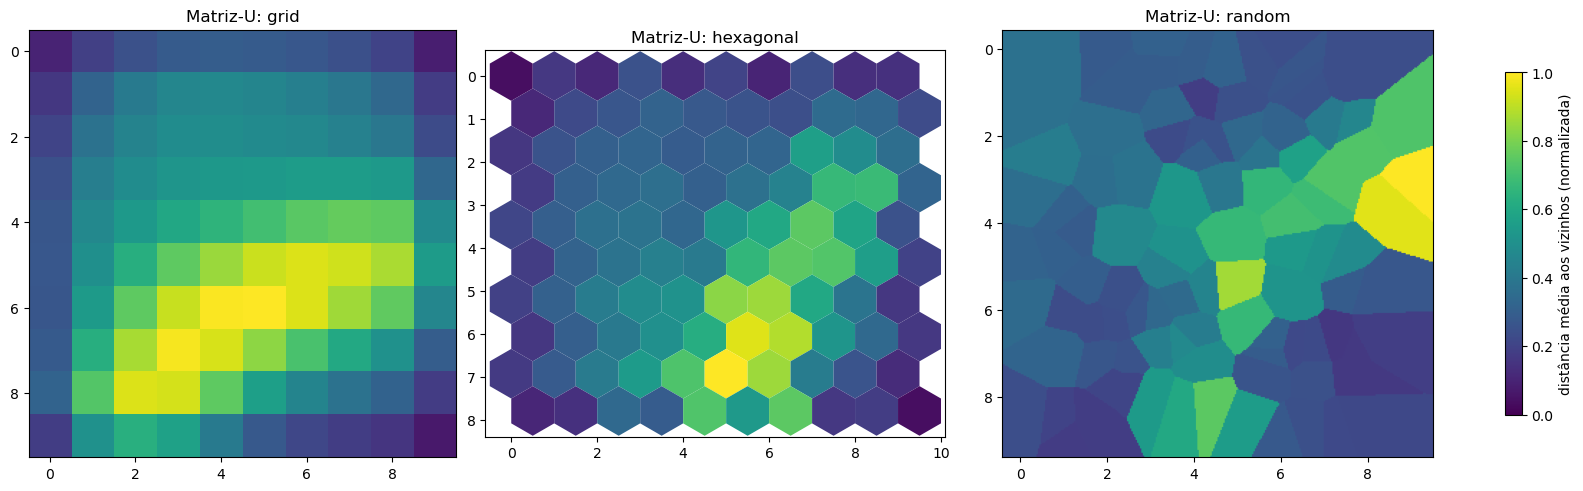

In [81]:
from matplotlib.patches import RegularPolygon
from matplotlib.collections import PatchCollection
from scipy.spatial import cKDTree

def plot_umatrix(ax, som, um, cmap="viridis"):
    """Desenha a matriz-U como células preenchidas, respeitando a topologia."""
    if som.topology == "grid":
        return ax.imshow(um, cmap=cmap, vmin=0, vmax=1, interpolation="nearest")

    if som.topology == "hexagonal":
        R = 1 / math.sqrt(3)     # raio do hexágono para encaixar com espaçamento 1
        patches = [RegularPolygon(som.pos[i][j], 6, radius=R)
                   for i in range(som.lines) for j in range(som.columns)]
        pc = PatchCollection(patches, cmap=cmap, edgecolor="none")
        pc.set_array(um.flatten()); pc.set_clim(0, 1)
        ax.add_collection(pc)
        ax.set_xlim(-0.6, som.columns + 0.1)
        ax.set_ylim(-0.6, (som.lines - 1) * math.sqrt(3) / 2 + 0.6)
        ax.invert_yaxis(); ax.set_aspect("equal")
        return pc

    # random: Voronoi (cada pixel recebe o valor do neurônio mais próximo)
    pts = np.array([som.pos[i][j] for i in range(som.lines) for j in range(som.columns)])
    xs = np.linspace(pts[:, 0].min() - 0.5, pts[:, 0].max() + 0.5, 300)
    ys = np.linspace(pts[:, 1].min() - 0.5, pts[:, 1].max() + 0.5, 300)
    gx, gy = np.meshgrid(xs, ys)
    _, idx = cKDTree(pts).query(np.c_[gx.ravel(), gy.ravel()])
    img = um.flatten()[idx].reshape(gx.shape)
    im = ax.imshow(img, cmap=cmap, vmin=0, vmax=1, origin="lower",
                   extent=[xs[0], xs[-1], ys[0], ys[-1]])
    ax.invert_yaxis(); ax.set_aspect("equal")
    return im


fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), constrained_layout=True)
for ax, topo in zip(axes, topologies):
    som = redes[topo]["som"]
    im = plot_umatrix(ax, som, u_matrix_ms(som))
    ax.set_title(f"Matriz-U: {topo}")
fig.colorbar(im, ax=axes, shrink=0.8, label="distância média aos vizinhos (normalizada)")
plt.show()

#### **Questão 4**

grid       | neurônios por cluster: [38 27 35]
hexagonal  | neurônios por cluster: [22 41 37]
random     | neurônios por cluster: [35 27 38]


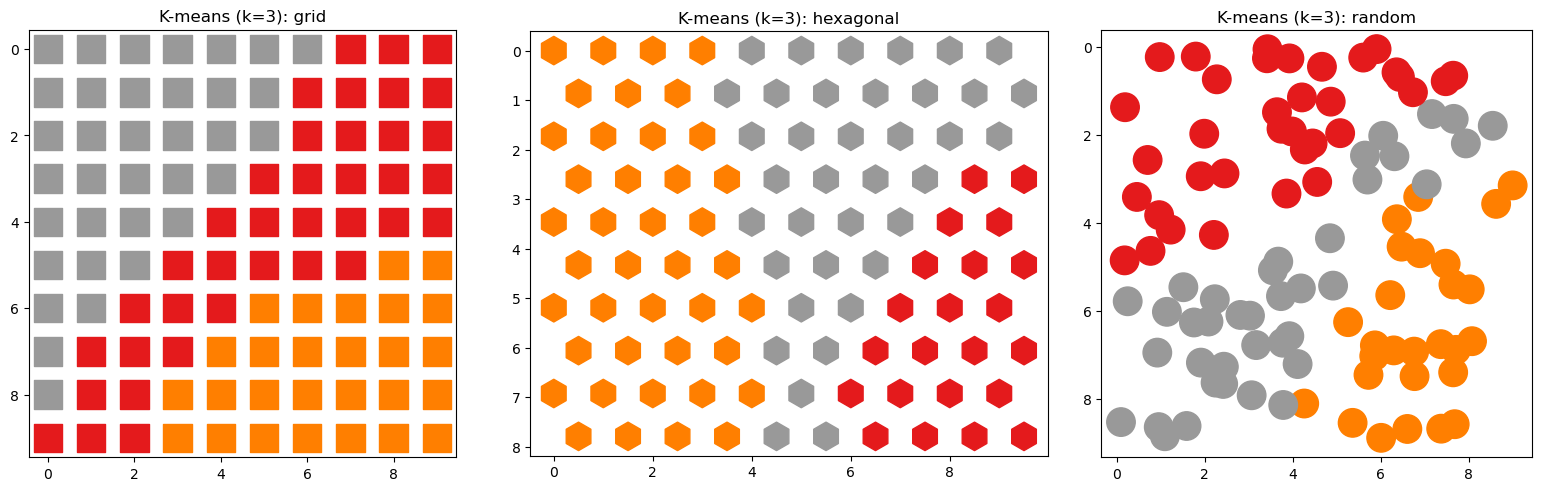

In [82]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), constrained_layout=True)

for ax, topo in zip(axes, topologies):
    som = redes[topo]["som"]
    W = np.array([som.weights[i][j] for i in range(som.lines) for j in range(som.columns)])
    km = KMeans(n_clusters=3, n_init=10, random_state=0).fit(W)
    redes[topo]["km"] = km

    xs, ys = pos_xy(som)
    ax.scatter(xs, ys, c=km.labels_, s=420, marker=marcador[topo], cmap="Set1")
    ax.set_title(f"K-means (k=3): {topo}")
    ax.invert_yaxis(); ax.set_aspect("equal")
    print(f"{topo:10s} | neurônios por cluster:", np.bincount(km.labels_, minlength=3))
plt.show()

#### **Questão 5**

In [ ]:
resumo = []
for topo in topologies:
    km = redes[topo]["km"]
    ctr = km.predict(np.array(Xtr_n))
    mapa = {c: np.bincount(np.array(ytr)[ctr == c], minlength=3).argmax() for c in range(3)}
    pred = np.array([mapa[c] for c in km.predict(np.array(Xte_n))])
    acc = np.mean(pred == np.array(yte))
    resumo.append({"topologia": topo, "acurácia": f"{acc:.2%}"})

    print(f"\n=== {topo} ===")
    print(pd.crosstab(pd.Series(yte, name="real").map(dict(enumerate(NOMES))),
                      pd.Series(pred, name="previsto").map(dict(enumerate(NOMES)))))

print("\nResumo:"); display(pd.DataFrame(resumo))


 5 *=== grid 5 * ===
previsto         Iris-setosa  Iris-versicolor  Iris-virginica
real                                                         
Iris-setosa                5                0               0
Iris-versicolor            0                1               4
Iris-virginica             0                0               5

 5 *=== hexagonal 5 * ===
previsto         Iris-setosa  Iris-virginica
real                                        
Iris-setosa                5               0
Iris-versicolor            0               5
Iris-virginica             0               5

 5 *=== random 5 * ===
previsto         Iris-setosa  Iris-versicolor  Iris-virginica
real                                                         
Iris-setosa                5                0               0
Iris-versicolor            0                1               4
Iris-virginica             0                1               4

Resumo:


,topologia,acurácia
0,grid,73.33%
1,hexagonal,66.67%
2,random,66.67%
